# FQGAN Demo (颜色直方图引导生成)

1. 环境与依赖检查
2. 参数与路径配置 (**只需要 `PT_PATH` + `TARGET_PATH`**)
3. 加载 FQGAN
4. Target 图像预览 + 提取目标颜色直方图
5. 生成 + 保存最终图像
6. 颜色指标评估 (RGBuvHist Hellinger + Mean Color L1)

## 1. 环境与依赖检查

In [1]:
import os, sys, time, re
from pathlib import Path
from datetime import datetime
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
from torchvision.utils import save_image
import matplotlib.pyplot as plt

# 让 FQGAN 项目根目录可被 import
PROJECT_ROOT = r"E:\备份\his\0416"
sys.path.insert(0, PROJECT_ROOT)

print('Python      :', sys.version.split()[0])
print('PyTorch     :', torch.__version__)
print('CUDA 可用   :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU         :', torch.cuda.get_device_name(0))
    torch.cuda.set_device(0)

device = torch.cuda.current_device() if torch.cuda.is_available() else torch.device('cpu')
print('使用设备    :', device)

Python      : 3.11.4
PyTorch     : 2.1.0+cu121
CUDA 可用   : True
GPU         : NVIDIA GeForce RTX 4050 Laptop GPU
使用设备    : 0


## 2. 参数与路径配置

> **只需要填两个路径**:训练好的 `.pt` 权重 和 目标颜色风格的图。
> 其余 hist / image_size 超参与训练时保持一致 (FQGAN 默认 Flower 配置)。

In [2]:
# === 在这里改 ===
PT_PATH     = r"E:\备份\his\0416\models\flower\model_10.pt"
TARGET_PATH = r"E:\备份\his\0416\target_images\6.jpg"
OUTPUT_DIR  = r"E:\备份\his\0416\results_demo"

# === FQGAN 超参 (与训练保持一致) ===
IMAGE_SIZE       = 128
NETWORK_CAPACITY = 16
HIST_BIN         = 64
HIST_INSZ        = 150
HIST_METHOD      = 'inverse-quadratic'
HIST_RESIZING    = 'interpolation'
HIST_SIGMA       = 0.02
TRUNC_PSI        = 0.75

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 路径自检
for tag, p in [('PT', PT_PATH), ('TARGET', TARGET_PATH)]:
    flag = '存在' if os.path.exists(p) else '缺失'
    print(f'[{flag}] {tag:7s} -> {p}')

# 从 PT_PATH 拆出 name / models_dir / load_from 给 Trainer.load 用
pt = Path(PT_PATH)
NAME        = pt.parent.name                       # e.g. "flower"
MODELS_DIR  = str(pt.parent.parent)                # e.g. r"E:\备份\his\0416\models"
_m = re.match(r'model_(\d+)\.pt', pt.name)
LOAD_FROM   = int(_m.group(1)) if _m else -1
print(f'NAME={NAME}  MODELS_DIR={MODELS_DIR}  LOAD_FROM={LOAD_FROM}')

[存在] PT      -> E:\备份\his\0416\models\flower\model_10.pt
[存在] TARGET  -> E:\备份\his\0416\target_images\6.jpg
NAME=flower  MODELS_DIR=E:\备份\his\0416\models  LOAD_FROM=10


## 3. 加载 FQGAN

- `Trainer` 内部会在 `MODELS_DIR/NAME/model_{LOAD_FROM}.pt` 找权重并加载
- 同时构造 `RGBuvHistBlock` 用于把图像 → 颜色直方图

In [3]:
from fqgan import Trainer
from histogram_classes.RGBuvHistBlock import RGBuvHistBlock

model = Trainer(
    name=NAME,
    results_dir=OUTPUT_DIR,
    models_dir=MODELS_DIR,
    image_size=IMAGE_SIZE,
    network_capacity=NETWORK_CAPACITY,
    transparent=False,
    batch_size=1,
    gradient_accumulate_every=1,
    lr=2e-4,
    num_workers=None,
    save_every=1000,
    trunc_psi=TRUNC_PSI,
    fp16=False,
    fq_layers=[],
    fq_dict_size=256,
    attn_layers=[],
    hist_method=HIST_METHOD,
    hist_resizing=HIST_RESIZING,
    hist_sigma=HIST_SIGMA,
    hist_bin=HIST_BIN,
    hist_insz=HIST_INSZ,
)
model.load(LOAD_FROM)
print(f'权重已加载: {PT_PATH}')

# 单独构一个 histblock 用于后面提取 target 直方图 + 算指标
histblock = RGBuvHistBlock(insz=HIST_INSZ, h=HIST_BIN, resizing=HIST_RESIZING,
                           method=HIST_METHOD, sigma=HIST_SIGMA, device=device)

D:\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


E:\备份\his\0416\models\flower\model_10.pt
权重已加载: E:\备份\his\0416\models\flower\model_10.pt


## 3.5 ColorGeneratorBlock 结构

每个 block 把输入拆成 **低频 / 高频** 两路独立处理后融合:

1. **Upsample 2×** → `AvgPool` 下采样 → resize 回去得 `low`,残差 `input - low` 即 `high`
2. **低频路**: `low` 走两个 `Conv2DMod`(modulated 3×3 conv),style 向量 `istyle` 经 `to_style11 / to_style12` 调制卷积核
3. **高频路**: `high` 走 5×5 + (3×3 → activation → 3×3) 残差路径,完全没有 style 调制 —— 保留结构
4. **融合**: `concat([low, high])` → 3×3 conv → `CA`(channel attention) → 1×1 conv 压回 filter 数
5. **to_rgb** 把当前特征图渲染成 RGB,累加到上一层的 RGB 输出

`forward(input, prev_rgb, istyle, inoise, latent=None)` 返回 `(x, rgb)`。

In [5]:
import sys, inspect
sys.path.insert(0, r"E:\备份\his\0416")  # 让 fqgan 包可被 import

from fqgan.fqgan import ColorGeneratorBlock

print(inspect.getsource(ColorGeneratorBlock))

class ColorGeneratorBlock(nn.Module):
  def __init__(self, latent_dim, input_channels, filters, upsample=True,
               upsample_rgb=True, rgba=False):
    super().__init__()


    self.upsample = nn.Upsample(scale_factor=2, mode='bilinear',
                                align_corners=False) if upsample else None
    self.down = nn.AvgPool2d(kernel_size=2)
    self.to_style11 = nn.Linear(latent_dim, input_channels)
    self.to_noise1 = nn.Linear(1, filters)
    self.conv11 = Conv2DMod(input_channels, filters, 3)

    self.to_style12 = nn.Linear(latent_dim, filters)
    self.to_noise2 = nn.Linear(1, filters)
    self.conv12 = Conv2DMod(filters, input_channels, 3)
    self.convh1 = nn.Conv2d(input_channels,input_channels,5,1,2)
    self.convh21 = nn.Conv2d(input_channels,filters,3,1,1)
    self.convh22 =  nn.Conv2d(filters,input_channels,3,1,1)


    # self.to_style21 = nn.Linear(latent_dim, input_channels)
    # # self.to_noise1 = nn.Linear(1, filters)
    # self.conv21 = Conv2D

## 4. Target 图像预览 + 提取目标颜色直方图

直接把 target 整图喂给 `RGBuvHistBlock`,得到引导生成用的颜色直方图(不再走调色板)。

Target size : (256, 256)
Target hist shape: (1, 3, 64, 64)


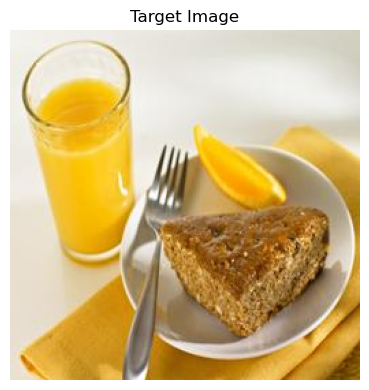

In [6]:
target_pil = Image.open(TARGET_PATH).convert('RGB')
print('Target size :', target_pil.size)

# 直接用 target 整图算直方图
target_t = transforms.ToTensor()(target_pil).to(device).unsqueeze(0)
h_target = histblock(target_t)
print('Target hist shape:', tuple(h_target.shape))

plt.figure(figsize=(4, 4))
plt.imshow(target_pil); plt.title('Target Image'); plt.axis('off')
plt.tight_layout(); plt.show()

## 5. 生成 + 保存最终图像

调用 `model.evaluate` 并取 `num_image_tiles=1`,只生成**一张** 128×128 图像,直接拿返回的 tensor 保存,不再依赖原来的网格 jpg。

生成尺寸: (1, 3, 256, 256)  耗时: 47.1 ms
结果已保存: E:\备份\his\0416\results_demo\generated-6-0519_223435.png


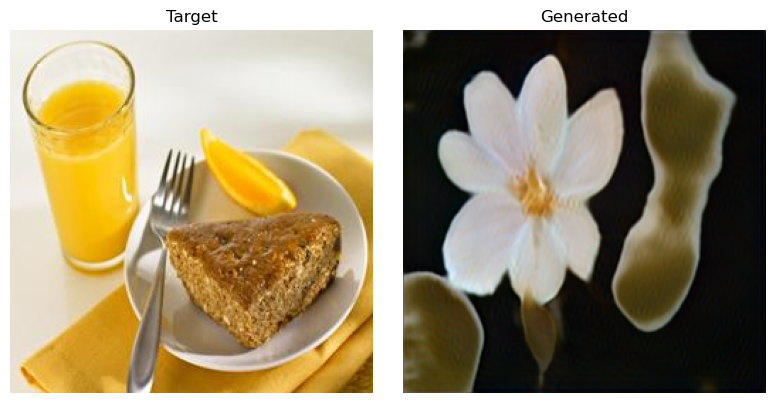

In [12]:
samples_name = f"generated-{Path(TARGET_PATH).stem}-{datetime.now().strftime('%m%d_%H%M%S')}"

torch.cuda.synchronize() if torch.cuda.is_available() else None
t0 = time.time()
with torch.no_grad():
    generated = model.evaluate(samples_name, hist_batch=h_target,
                               num_image_tiles=1, save_noise_latent=False,
                               load_noise_file=None, load_latent_file=None)
torch.cuda.synchronize() if torch.cuda.is_available() else None
dt = time.time() - t0

print(f'生成尺寸: {tuple(generated.shape)}  耗时: {dt*1000:.1f} ms')

# 单张输出 (1, 3, H, W)
output_tensor = generated[0:1].clamp(0, 1)
save_path = os.path.join(OUTPUT_DIR, f'{samples_name}.png')
save_image(output_tensor, save_path)
print(f'结果已保存: {save_path}')

# 两栏对比: target / output
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(target_pil); axes[0].set_title('Target');    axes[0].axis('off')
axes[1].imshow(output_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy())
axes[1].set_title('Generated'); axes[1].axis('off')
plt.tight_layout(); plt.show()

## 6. 颜色指标评估

只看颜色,不算结构 / 纹理:

- **HistLoss (RGBuvHist Hellinger)**:目标图与生成图的颜色直方图距离,与 FQGAN 训练时用的损失同源,越小越接近
- **Mean Color L1**:RGB 通道均值的 L1 差异,作为粗糙 sanity check

In [13]:
# 直接比对 "target 整图颜色分布" vs "生成图颜色分布"
# (h_target 已经是 target 整图的直方图, 直接复用)
h_generated = histblock(output_tensor.to(device))

# Hellinger distance on sqrt-histograms (与 metrics.ColorHistLoss 同公式)
with torch.no_grad():
    hist_loss = (1.0 / np.sqrt(2.0)) * torch.sqrt(
        ((torch.sqrt(h_target + 1e-8) - torch.sqrt(h_generated + 1e-8)) ** 2).sum()
    ).item()

    mean_t = target_t.mean(dim=(2, 3))
    mean_o = output_tensor.to(device).mean(dim=(2, 3))
    mean_l1 = (mean_t - mean_o).abs().mean().item()

print('=' * 40)
print('颜色指标 (target ↔ generated)')
print('-' * 40)
print(f'  RGBuvHist Hellinger : {hist_loss:.4f}')
print(f'  Mean Color L1       : {mean_l1:.4f}')
print('=' * 40)

颜色指标 (target ↔ generated)
----------------------------------------
  RGBuvHist Hellinger : 0.3204
  Mean Color L1       : 0.3929
